# Image Retrieval on MIRFLICKR-25K — Feature Extraction, Similarity Search, and Clustering

This project builds a **content-based image retrieval (CBIR) system** on the [MIRFLICKR-25K](http://press.liacs.nl/mirflickr/) dataset (25,000 Flickr images with user tags and expert annotations).

It covers the full pipeline: extracting visual and semantic features (MPEG-7 descriptors + OpenCLIP embeddings), building multiple retrieval methods (k-NN, text-to-image, LSH-based approximate search), applying dimensionality reduction (PCA, SVD), and evaluating unsupervised clustering (DBSCAN, Spectral Clustering — both implemented from scratch).

**Feature representations used:**
- MPEG-7 Edge Histogram (150-d) and Homogeneous Texture (43-d) — classical hand-crafted descriptors
- OpenCLIP ViT-B-32 embeddings (512-d) — learned representations for images, tags, annotations, and a weighted fusion
- PCA-fused and SVD-fused hybrid representations (512-d) — combining all of the above

---

## 0 — Data Exploration

In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import open_clip
import pickle

DATA_DIR = "./data"
IMAGE_DIR = os.path.join(DATA_DIR, "mirflickr")
TAGS_DIR = os.path.join(IMAGE_DIR, "meta", "tags")
ANNOTATIONS_DIR = os.path.join(DATA_DIR, "mirflickr25k_annotations_v080")
EDGE_HIST_DIR = os.path.join(DATA_DIR, "features_edgehistogram")
HOMO_TEX_DIR = os.path.join(DATA_DIR, "features_homogeneoustexture")
FEATURES_DIR = "./features"

N_IMAGES = 25000

print("Setup OK")

Setup OK


In [2]:
for name, path in [("Images", IMAGE_DIR), 
                    ("Tags", TAGS_DIR), 
                    ("Annotations", ANNOTATIONS_DIR),
                    ("Edge Histogram", EDGE_HIST_DIR), 
                    ("Homogeneous Texture", HOMO_TEX_DIR)]:
    if os.path.isdir(path):
        print(f"[OK] {name}: {path}")
    else:
        print(f"[MISSING] {name}: {path}")

[OK] Images: ./data\mirflickr
[OK] Tags: ./data\mirflickr\meta\tags
[OK] Annotations: ./data\mirflickr25k_annotations_v080
[OK] Edge Histogram: ./data\features_edgehistogram
[OK] Homogeneous Texture: ./data\features_homogeneoustexture


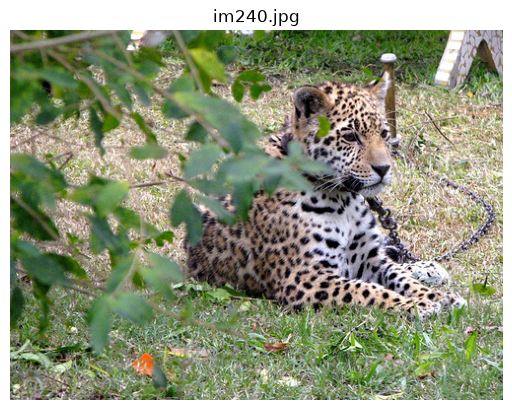

User tags: ['yaguarete', 'cautiverio', 'jaguar', 'explore']
Annotations: ['animals', 'plant_life']


In [3]:
SAMPLE_IMG_NUM = 240

img_filename = f"im{SAMPLE_IMG_NUM}.jpg"
img = Image.open(os.path.join(IMAGE_DIR, img_filename))
plt.imshow(img)
plt.title(img_filename)
plt.axis("off")
plt.show()

# User tags
tags_file = os.path.join(TAGS_DIR, f"tags{SAMPLE_IMG_NUM}.txt")
with open(tags_file, "r", encoding="utf-8", errors="ignore") as f:
    tags = [line.strip() for line in f if line.strip()]
print(f"User tags: {tags}")

# Expert annotations
annotations = []
for ann_file in os.listdir(ANNOTATIONS_DIR):
    if ann_file.startswith(".") or ann_file.endswith("_r1.txt"):
        continue
    filepath = os.path.join(ANNOTATIONS_DIR, ann_file)
    if os.path.isfile(filepath):
        with open(filepath, "r") as f:
            ids = [line.strip() for line in f]
            if str(SAMPLE_IMG_NUM) in ids:
                annotations.append(ann_file.replace(".txt", ""))
print(f"Annotations: {annotations}")

### Raw MPEG-7 descriptor files
The dataset ships pre-computed MPEG-7 descriptors as plain text files (one float per line). Quick sanity check on structure and dimensions before writing the extraction functions.

In [4]:
img_number = 238
desc_index = img_number - 1
folder = str(desc_index // 10000)

# Edge Histogram
eh_path = os.path.join(EDGE_HIST_DIR, folder, f"{desc_index}.txt")
with open(eh_path, "r") as f:
    eh_values = [float(line.strip()) for line in f if line.strip()]
print(f"Edge Histogram file: {eh_path}")
print(f"  Total values in file: {len(eh_values)}")

# Homogeneous Texture (full MPEG-7 standard is 62, but MIRFLICKR ships a reduced 43-d version)
ht_path = os.path.join(HOMO_TEX_DIR, folder, f"{desc_index}.txt")
with open(ht_path, "r") as f:
    ht_values = [float(line.strip()) for line in f if line.strip()]
print(f"\nHomogeneous Texture file: {ht_path}")
print(f"  Total values in file: {len(ht_values)}")

Edge Histogram file: ./data\features_edgehistogram\0\237.txt
  Total values in file: 150

Homogeneous Texture file: ./data\features_homogeneoustexture\0\237.txt
  Total values in file: 43


## 1 — Single-Image Feature Extraction

Given an image and a model name, extract the feature vector and display both the image and the descriptor.

Two types of models:
- **MPEG-7** (Edge Histogram 150-d, Homogeneous Texture 43-d): pre-computed, read from disk.
- **OpenCLIP** (Image, TagText, AnnotationText, Fused — all 512-d): computed live through a Vision Transformer. All four share the same embedding space, so image and text vectors are directly comparable via cosine similarity.

### Loading OpenCLIP

Loaded once up front — reloading per image would be way too slow. `ViT-B-32` is the architecture (Vision Transformer, 32×32 patches), trained on ~2B image-text pairs. Same encoder puts images and text into the same 512-d space.

In [4]:
CLIP_MODEL_NAME = "ViT-B-32"
CLIP_PRETRAINED = "laion2b_s34b_b79k"
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, preprocess = open_clip.create_model_and_transforms(
    CLIP_MODEL_NAME, pretrained=CLIP_PRETRAINED
)

model = model.to(device)
model.eval()
tokenizer = open_clip.get_tokenizer(CLIP_MODEL_NAME)

print(f"Model loaded: {CLIP_MODEL_NAME} on {device}")

Model loaded: ViT-B-32 on cpu


### Helper functions
Utilities for looking up image metadata: `get_descriptor_path` handles the N-1 index offset and subfolder routing, `get_tags` reads user tags, `get_annotations` scans concept files for expert labels.

In [5]:
def get_descriptor_path(base_dir, img_number):
    """Descriptor files are 0-indexed (im1.jpg -> 0.txt), split into subfolders of 10k."""
    desc_index = img_number - 1
    folder = str(desc_index // 10000)
    return os.path.join(base_dir, folder, f"{desc_index}.txt")

def get_tags(img_number):
    """Read user tags for an image. Returns empty list if no file exists."""
    tags_file = os.path.join(TAGS_DIR, f"tags{img_number}.txt")
    if os.path.exists(tags_file):
        with open(tags_file, "r", encoding="utf-8", errors="ignore") as f:
            return [line.strip() for line in f if line.strip()]
    return []

def get_annotations(img_number):
    """Check each concept file to see if this image is listed."""
    annotations = []
    for ann_file in os.listdir(ANNOTATIONS_DIR):
        if ann_file.startswith(".") or ann_file.endswith("_r1.txt"):
            continue
        filepath = os.path.join(ANNOTATIONS_DIR, ann_file)
        if os.path.isfile(filepath):
            with open(filepath, "r") as f:
                if str(img_number) in [line.strip() for line in f]:
                    annotations.append(ann_file.replace(".txt", ""))
    return annotations

print(f"Tags for im238: {get_tags(238)}")
print(f"Annotations for im238: {get_annotations(238)}")

Tags for im238: ['sw', 'strümpfe', 'beine', 'indoor']
Annotations for im238: ['female', 'indoor', 'people']


### MPEG-7 extractors
Pre-computed descriptors read from disk. `extract_edge_histogram` returns 150 values, `extract_homogeneous_texture` returns 43. These are low-level hand-crafted features (edges, texture frequency), unlike the learned CLIP embeddings.

In [6]:
def extract_edge_histogram(img_number):
    """MPEG-7 Edge Histogram: 150 dims."""
    path = get_descriptor_path(EDGE_HIST_DIR, img_number)
    with open(path, "r") as f:
        values = [float(line.strip()) for line in f if line.strip()]
    return np.array(values)

def extract_homogeneous_texture(img_number):
    """MPEG-7 Homogeneous Texture: 43 dims (reduced version shipped with this dataset)."""
    path = get_descriptor_path(HOMO_TEX_DIR, img_number)
    with open(path, "r") as f:
        values = [float(line.strip()) for line in f if line.strip()]
    return np.array(values)

TEST_IMG_NUM = 50

eh = extract_edge_histogram(TEST_IMG_NUM)
ht = extract_homogeneous_texture(TEST_IMG_NUM)
print(f"Edge Histogram: {eh.shape[0]} dims, first 5: {eh[:5]}")
print(f"Homogeneous Texture: {ht.shape[0]} dims, first 5: {ht[:5]}")

Edge Histogram: 150 dims, first 5: [0.0585938 0.222656  0.03125   0.0195313 0.0585938]
Homogeneous Texture: 43 dims, first 5: [1.0232  1.2182  1.11846 1.06289 1.03579]


### OpenCLIP extractors

Four extraction functions:
- `extract_clip_image` — pixels through the visual encoder → 512-d
- `extract_clip_tag_text` — joined user tags through the text encoder → 512-d (zero vector if no tags)
- `extract_clip_annotation_text` — same idea but with expert annotations
- `extract_clip_fused` — weighted combination (0.5 image + 0.25 tag + 0.25 annotation), re-normalized

All outputs are L2-normalized so cosine similarity reduces to a dot product.

In [7]:
def extract_clip_image(img_number):
    """Encode image pixels into a 512-d CLIP vector."""
    img_path = os.path.join(IMAGE_DIR, f"im{img_number}.jpg")
    img = Image.open(img_path).convert("RGB")
    img_tensor = preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        features = model.encode_image(img_tensor)
    features = features / features.norm(dim=-1, keepdim=True)
    return features.cpu().numpy().flatten()

def extract_clip_tag_text(img_number):
    """Encode user tags as text into the same 512-d space."""
    tags = get_tags(img_number)
    if not tags:
        return np.zeros(512)
    tokens = tokenizer([" ".join(tags)]).to(device)
    with torch.no_grad():
        features = model.encode_text(tokens)
    features = features / features.norm(dim=-1, keepdim=True)
    return features.cpu().numpy().flatten()

def extract_clip_annotation_text(img_number):
    """Encode expert annotations into the same 512-d space."""
    anns = get_annotations(img_number)
    if not anns:
        return np.zeros(512)
    tokens = tokenizer([" ".join(anns)]).to(device)
    with torch.no_grad():
        features = model.encode_text(tokens)
    features = features / features.norm(dim=-1, keepdim=True)
    return features.cpu().numpy().flatten()

def extract_clip_fused(img_number):
    """Weighted average of image (0.5), tag (0.25), and annotation (0.25) embeddings."""
    vec_img = extract_clip_image(img_number)
    vec_tag = extract_clip_tag_text(img_number)
    vec_ann = extract_clip_annotation_text(img_number)
    fused = 0.5 * vec_img + 0.25 * vec_tag + 0.25 * vec_ann
    norm = np.linalg.norm(fused)
    return fused / norm if norm > 0 else fused

TEST_IMG_NUM = 238

vec = extract_clip_image(TEST_IMG_NUM)
print(f"CLIP Image: {vec.shape[0]} dims, first 5: {vec[:5]}")
vec = extract_clip_tag_text(TEST_IMG_NUM)
print(f"CLIP TagText: {vec.shape[0]} dims, first 5: {vec[:5]}")
vec = extract_clip_annotation_text(TEST_IMG_NUM)
print(f"CLIP AnnotationText: {vec.shape[0]} dims, first 5: {vec[:5]}")
vec = extract_clip_fused(TEST_IMG_NUM)
print(f"CLIP Fused: {vec.shape[0]} dims, first 5: {vec[:5]}")

CLIP Image: 512 dims, first 5: [ 0.01041026  0.13880849 -0.10218588  0.00483817 -0.018041  ]
CLIP TagText: 512 dims, first 5: [ 0.00495078 -0.03988759 -0.0012625  -0.02421067  0.03486668]
CLIP AnnotationText: 512 dims, first 5: [ 0.04673684  0.01886597  0.0238996  -0.03381237  0.00893311]
CLIP Fused: 512 dims, first 5: [ 0.0247727   0.08766686 -0.06209039 -0.01651785  0.00263681]


### Dispatcher
`FEATURE_MODELS` maps each model name to its extraction function. Given an image and model name, we display the image and print the feature vector.

In [8]:
FEATURE_MODELS = {
    "MIRFLICKR-EdgeHistogram-150": extract_edge_histogram,
    "MIRFLICKR-HomogeneousTexture-43": extract_homogeneous_texture,
    "OpenCLIP-Image-512": extract_clip_image,
    "OpenCLIP-TagText-512": extract_clip_tag_text,
    "OpenCLIP-AnnotationText-512": extract_clip_annotation_text,
    "OpenCLIP-Fused-512": extract_clip_fused,
}

def task1(img_filename, model_name):
    img_number = int(img_filename.replace("im", "").replace(".jpg", ""))

    img = Image.open(os.path.join(IMAGE_DIR, img_filename))
    plt.imshow(img)
    plt.title(f"{img_filename} — {model_name}")
    plt.axis("off")
    plt.show()

    extract_fn = FEATURE_MODELS[model_name]
    vec = extract_fn(img_number)
    print(f"Model: {model_name}")
    print(f"Dimensions: {vec.shape[0]}")
    print(f"Feature vector:\n{vec}")

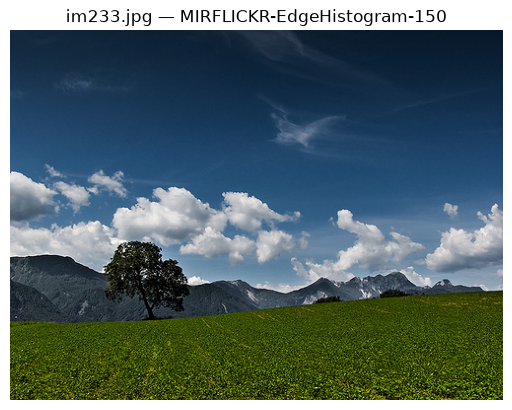

Model: MIRFLICKR-EdgeHistogram-150
Dimensions: 150
Feature vector:
[0.00390625 0.0273438  0.00390625 0.0078125  0.0117188  0.
 0.         0.         0.0078125  0.00390625 0.0078125  0.0390625
 0.015625   0.0390625  0.0273438  0.         0.         0.
 0.         0.         0.0351563  0.101563   0.0625     0.0820313
 0.140625   0.0429688  0.0742188  0.0429688  0.0273438  0.0742188
 0.0351563  0.0585938  0.0273438  0.0234375  0.0273438  0.0117188
 0.0234375  0.0078125  0.0195313  0.0078125  0.144531   0.195313
 0.109375   0.0664063  0.3125     0.144531   0.25       0.117188
 0.132813   0.230469   0.113281   0.285156   0.101563   0.117188
 0.230469   0.0820313  0.265625   0.09375    0.0859375  0.257813
 0.101563   0.125      0.0976563  0.0898438  0.511719   0.0703125
 0.109375   0.105469   0.0898438  0.519531   0.0976563  0.136719
 0.0742188  0.101563   0.472656   0.0664063  0.0703125  0.09375
 0.09375    0.597656   0.299072   0.550537   0.297852   0.307617
 1.07056    0.0712891  0.112305

In [10]:
task1("im233.jpg", "MIRFLICKR-EdgeHistogram-150")

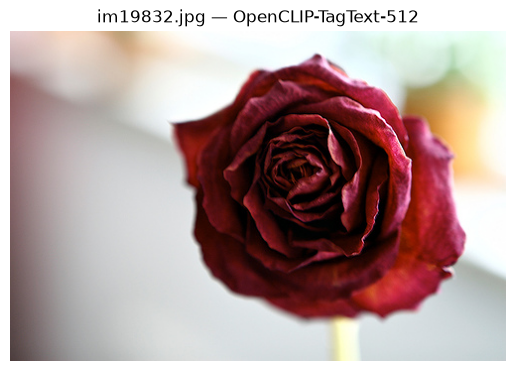

Model: OpenCLIP-TagText-512
Dimensions: 512
Feature vector:
[-1.00838738e-02  2.22141948e-02 -4.19215895e-02 -6.90501705e-02
 -1.97826196e-02 -2.27560066e-02  8.14275816e-03  1.27899125e-02
  4.51099500e-02 -5.04909717e-02  4.33305688e-02 -2.09854287e-03
  2.32198276e-02  2.57857181e-02 -4.04866561e-02 -4.20909338e-02
  2.89489124e-02 -3.68568301e-02 -1.35100621e-03 -3.10654975e-02
  5.54740475e-03 -2.38580443e-02  4.89180870e-02 -2.47059739e-03
  2.36263424e-02  4.38280143e-02  6.62297830e-02 -3.18343751e-02
  4.23156954e-02  7.94012938e-03 -1.13108912e-02 -1.54050291e-02
  5.02258213e-03  2.88193929e-04 -5.10698417e-03 -4.32312787e-02
 -1.75704956e-02 -9.26903039e-02  1.73705537e-02 -9.30439308e-03
  2.33013872e-02 -3.51407081e-02  4.41028774e-02 -6.07394986e-03
  5.87226765e-04 -5.81448562e-02  7.62765184e-02  7.54739568e-02
  2.17011827e-03 -2.24630609e-02 -2.88635995e-02  5.23518287e-02
 -7.81185254e-02 -5.24421595e-02 -1.34512961e-01 -2.80359015e-02
 -3.68921482e-03  4.39105146e-

In [11]:
task1("im19832.jpg", "OpenCLIP-TagText-512")

task1("im11111.jpg", "OpenCLIP-Fused-512")

## 2 — Batch Feature Extraction (25K images)

The single-image extraction from Section 1 is great for inspection, but we need feature matrices for the full dataset. This section runs extraction over all 25,000 images and saves the results as `.npy` files for downstream tasks.

### Annotation index (inverted lookup)
Instead of scanning every concept file per image (way too slow at 25K scale), we read each file once into a `{concept: set(image_ids)}` dictionary. Lookup becomes O(1).

In [11]:
# Build inverted annotation index: {concept: set of image IDs}
annotation_index = {}
for ann_file in os.listdir(ANNOTATIONS_DIR):
    if ann_file.startswith(".") or ann_file.endswith("_r1.txt"):
        continue
    filepath = os.path.join(ANNOTATIONS_DIR, ann_file)
    if os.path.isfile(filepath):
        concept = ann_file.replace(".txt", "")
        with open(filepath, "r") as f:
            annotation_index[concept] = set(line.strip() for line in f if line.strip())

def get_annotations_indexed(img_number):
    return [c for c, ids in annotation_index.items() if str(img_number) in ids]

all_filenames = [f"im{i}.jpg" for i in range(1, N_IMAGES + 1)]
all_tags = [get_tags(i) for i in range(1, N_IMAGES + 1)]
all_annotations = [get_annotations_indexed(i) for i in range(1, N_IMAGES + 1)]

print(f"Done. {len(all_filenames)} images.")
print(f"Sample — im238.jpg tags: {all_tags[237]}")
print(f"Sample — im238.jpg annotations: {all_annotations[237]}")

Done. 25000 images.
Sample — im238.jpg tags: ['sw', 'strümpfe', 'beine', 'indoor']
Sample — im238.jpg annotations: ['female', 'indoor', 'people']


### Batch MPEG-7 extraction
Read directly from pre-computed files (no model inference). Stack into matrices and save as `.npy` for reuse.

In [ ]:
# Edge Histogram (150-d) for all images
eh_features = []
for i in range(1, N_IMAGES + 1):
    path = get_descriptor_path(EDGE_HIST_DIR, i)
    with open(path, "r") as f:
        values = [float(line.strip()) for line in f if line.strip()]
    eh_features.append(values)
eh_features = np.array(eh_features)
np.save(os.path.join(FEATURES_DIR, "MIRFLICKR-EdgeHistogram-150.npy"), eh_features)
print(f"Edge Histogram: {eh_features.shape}")

# Homogeneous Texture (43-d) for all images
ht_features = []
for i in range(1, N_IMAGES + 1):
    path = get_descriptor_path(HOMO_TEX_DIR, i)
    with open(path, "r") as f:
        values = [float(line.strip()) for line in f if line.strip()]
    ht_features.append(values)
ht_features = np.array(ht_features)
np.save(os.path.join(FEATURES_DIR, "MIRFLICKR-HomogeneousTexture.npy"), ht_features)
print(f"Homogeneous Texture: {ht_features.shape}")

### Batch OpenCLIP image embeddings
Processed in batches of 32 to keep memory usage reasonable.

In [ ]:
BATCH_SIZE = 32
clip_image_features = []

for batch_start in range(0, N_IMAGES, BATCH_SIZE):
    batch_end = min(batch_start + BATCH_SIZE, N_IMAGES)
    batch_images = []
    for i in range(batch_start + 1, batch_end + 1):
        img = Image.open(os.path.join(IMAGE_DIR, f"im{i}.jpg")).convert("RGB")
        batch_images.append(preprocess(img))
    batch_tensor = torch.stack(batch_images).to(device)
    with torch.no_grad():
        features = model.encode_image(batch_tensor)
    features = features / features.norm(dim=-1, keepdim=True)
    clip_image_features.append(features.cpu().numpy())

clip_image_features = np.vstack(clip_image_features)
np.save(os.path.join(FEATURES_DIR, "OpenCLIP-Image-512.npy"), clip_image_features)
print(f"OpenCLIP Image: {clip_image_features.shape}")

### Batch OpenCLIP text embeddings (tags + annotations)
Same encoder, different input — user tags and expert annotations go through CLIP's text encoder. Images with no tags/annotations get a zero vector as a neutral placeholder so every image keeps a vector in every feature space.

In [ ]:
def batch_encode_texts(text_list, batch_size=64):
    """Encode a list of strings into L2-normalized 512-d CLIP vectors.
    Empty strings get a zero vector."""
    n = len(text_list)
    all_features = np.zeros((n, 512), dtype=np.float32)

    nonempty_idx = [i for i, t in enumerate(text_list) if t.strip()]
    nonempty_texts = [text_list[i] for i in nonempty_idx]

    for start in range(0, len(nonempty_texts), batch_size):
        batch_texts = nonempty_texts[start:start + batch_size]
        batch_indices = nonempty_idx[start:start + batch_size]

        tokens = tokenizer(batch_texts).to(device)
        with torch.no_grad():
            features = model.encode_text(tokens)
        features = features / features.norm(dim=-1, keepdim=True)
        features = features.cpu().numpy()

        for j, idx in enumerate(batch_indices):
            all_features[idx] = features[j]

    return all_features

tag_strings = [" ".join(tags) if tags else "" for tags in all_tags]
ann_strings = [" ".join(anns) if anns else "" for anns in all_annotations]

clip_tag_features = batch_encode_texts(tag_strings)
np.save(os.path.join(FEATURES_DIR, "OpenCLIP-TagText-512.npy"), clip_tag_features)
print(f"OpenCLIP TagText: {clip_tag_features.shape}")

clip_ann_features = batch_encode_texts(ann_strings)
np.save(os.path.join(FEATURES_DIR, "OpenCLIP-AnnotationText-512.npy"), clip_ann_features)
print(f"OpenCLIP AnnotationText: {clip_ann_features.shape}")

### Fused embeddings + metadata
The fused vector combines image, tag, and annotation signals. Metadata (filenames, tags, annotations) is saved alongside for later retrieval.

In [ ]:
# Fused: weighted average of the three CLIP vectors, re-normalized
clip_fused_features = (0.5 * clip_image_features + 
                       0.25 * clip_tag_features + 
                       0.25 * clip_ann_features)
norms = np.linalg.norm(clip_fused_features, axis=1, keepdims=True)
norms[norms == 0] = 1
clip_fused_features = clip_fused_features / norms
np.save(os.path.join(FEATURES_DIR, "OpenCLIP-Fused-512.npy"), clip_fused_features)
print(f"OpenCLIP Fused: {clip_fused_features.shape}")

metadata = {
    "filenames": all_filenames,
    "tags": all_tags,
    "annotations": all_annotations,
}
with open(os.path.join(FEATURES_DIR, "metadata.pkl"), "wb") as f:
    pickle.dump(metadata, f)
print("Metadata saved.")

## 3 — Query by Example (k-NN Retrieval)

Given an image already in the dataset and a value k, retrieve the k most similar images under a chosen feature model.

Distance/similarity metric depends on the feature type:
- MPEG-7 descriptors → **Euclidean distance** (L2) — smaller = more similar
- OpenCLIP embeddings → **cosine similarity** — larger = more similar (works because vectors are L2-normalized)

### Loading saved features

In [9]:
eh_features = np.load(os.path.join(FEATURES_DIR, "MIRFLICKR-EdgeHistogram-150.npy"))
ht_features = np.load(os.path.join(FEATURES_DIR, "MIRFLICKR-HomogeneousTexture.npy"))
clip_image_features = np.load(os.path.join(FEATURES_DIR, "OpenCLIP-Image-512.npy"))
clip_tag_features = np.load(os.path.join(FEATURES_DIR, "OpenCLIP-TagText-512.npy"))
clip_ann_features = np.load(os.path.join(FEATURES_DIR, "OpenCLIP-AnnotationText-512.npy"))
clip_fused_features = np.load(os.path.join(FEATURES_DIR, "OpenCLIP-Fused-512.npy"))

with open(os.path.join(FEATURES_DIR, "metadata.pkl"), "rb") as f:
    metadata = pickle.load(f)
all_filenames = metadata["filenames"]
all_tags = metadata["tags"]
all_annotations = metadata["annotations"]

print(f"Loaded {len(all_filenames)} images across 6 feature spaces.")

Loaded 25000 images across 6 feature spaces.


### Distance and similarity functions
Euclidean for the MPEG-7 descriptors, cosine for the CLIP embeddings.

In [10]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def cosine_similarity(a, b):
    dot = np.dot(a, b)
    norm = np.linalg.norm(a) * np.linalg.norm(b)
    if norm == 0:
        return 0.0
    return dot / norm

MODELS = {
    "MIRFLICKR-EdgeHistogram-150": (eh_features, euclidean_distance, "distance"),
    "MIRFLICKR-HomogeneousTexture": (ht_features, euclidean_distance, "distance"),
    "OpenCLIP-Image-512": (clip_image_features, cosine_similarity, "similarity"),
    "OpenCLIP-TagText-512": (clip_tag_features, cosine_similarity, "similarity"),
    "OpenCLIP-AnnotationText-512": (clip_ann_features, cosine_similarity, "similarity"),
    "OpenCLIP-Fused-512": (clip_fused_features, cosine_similarity, "similarity"),
}

print(f"{len(MODELS)} models ready.")

6 models ready.


### k-NN search
For a query image, compute distance/similarity to every stored vector, sort, and keep the top k.

In [11]:
def find_k_nearest(img_filename, k, model_name):
    img_number = int(img_filename.replace("im", "").replace(".jpg", ""))
    img_index = img_number - 1

    features, measure_fn, measure_type = MODELS[model_name]
    query_vec = features[img_index]

    scores = []
    for i in range(len(features)):
        if i == img_index:
            continue
        score = measure_fn(query_vec, features[i])
        scores.append((i, score))

    if measure_type == "distance":
        scores.sort(key=lambda x: x[1])
    else:
        scores.sort(key=lambda x: x[1], reverse=True)

    return scores[:k]

### Visualization
Query image on the left, top-k matches displayed with their scores.

In [12]:
def task3(img_filename, k, model_name):
    results = find_k_nearest(img_filename, k, model_name)
    _, _, measure_type = MODELS[model_name]

    query_img = Image.open(os.path.join(IMAGE_DIR, img_filename))
    plt.figure(figsize=(3, 3))
    plt.imshow(query_img)
    plt.title(f"Query: {img_filename}")
    plt.axis("off")
    plt.show()

    print(f"Model: {model_name} ({measure_type})")
    print(f"Top {k} results:\n")

    fig, axes = plt.subplots(1, k, figsize=(3 * k, 3))
    if k == 1:
        axes = [axes]

    for idx, (img_index, score) in enumerate(results):
        filename = all_filenames[img_index]
        img = Image.open(os.path.join(IMAGE_DIR, filename))
        axes[idx].imshow(img)
        axes[idx].set_title(f"{score:.4f}")
        axes[idx].axis("off")
        print(f"  {idx+1}. {filename} — {measure_type}: {score:.4f}")

    plt.tight_layout()
    plt.show()

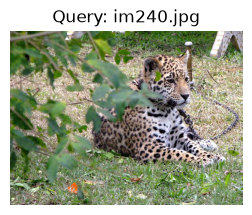

Model: MIRFLICKR-EdgeHistogram-150 (distance)
Top 5 results:

  1. im11834.jpg — distance: 0.4445
  2. im557.jpg — distance: 0.4473
  3. im10859.jpg — distance: 0.4571
  4. im3464.jpg — distance: 0.4698
  5. im21854.jpg — distance: 0.4733


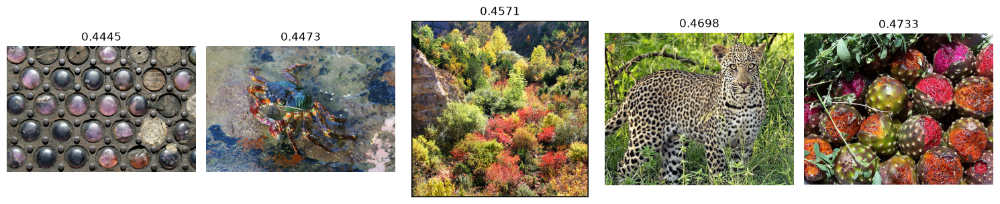

In [14]:
task3("im240.jpg", 5, "MIRFLICKR-EdgeHistogram-150")

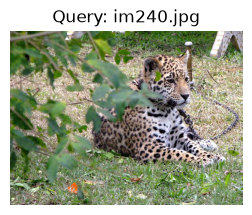

Model: MIRFLICKR-HomogeneousTexture (distance)
Top 5 results:

  1. im24563.jpg — distance: 0.1133
  2. im2836.jpg — distance: 0.1220
  3. im19848.jpg — distance: 0.1224
  4. im17970.jpg — distance: 0.1267
  5. im23824.jpg — distance: 0.1400


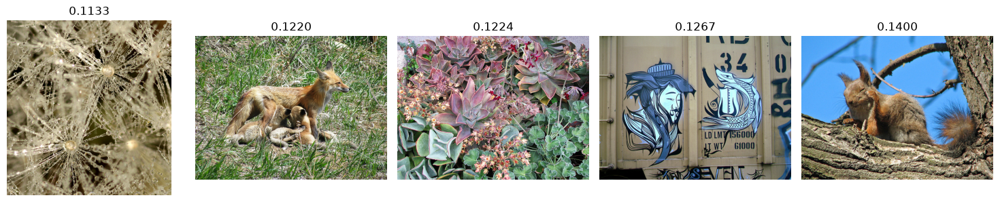

In [15]:
task3("im240.jpg", 5, "MIRFLICKR-HomogeneousTexture")

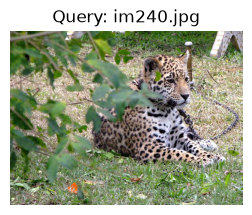

Model: OpenCLIP-TagText-512 (similarity)
Top 5 results:

  1. im18034.jpg — similarity: 0.6060
  2. im15945.jpg — similarity: 0.5927
  3. im17631.jpg — similarity: 0.5883
  4. im9325.jpg — similarity: 0.5545
  5. im22035.jpg — similarity: 0.5472


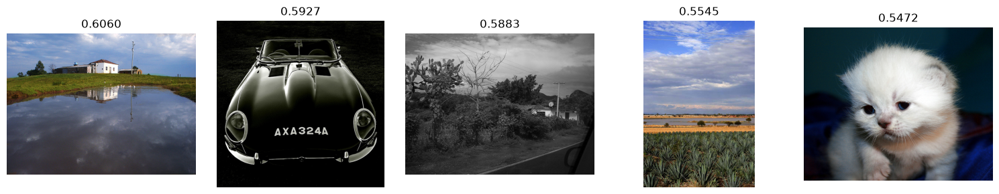

In [13]:
task3("im240.jpg", 5, "OpenCLIP-TagText-512")

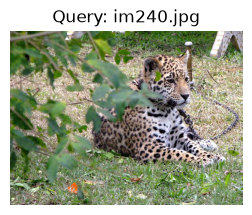

Model: OpenCLIP-AnnotationText-512 (similarity)
Top 5 results:

  1. im255.jpg — similarity: 1.0000
  2. im412.jpg — similarity: 1.0000
  3. im458.jpg — similarity: 1.0000
  4. im597.jpg — similarity: 1.0000
  5. im775.jpg — similarity: 1.0000


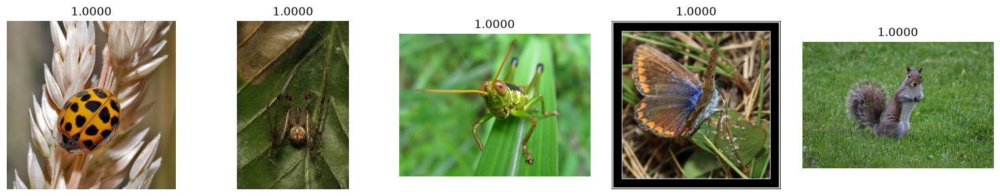

In [14]:
task3("im240.jpg", 5, "OpenCLIP-AnnotationText-512")

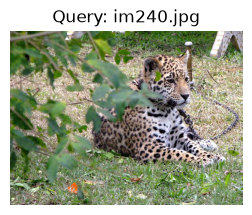

Model: OpenCLIP-Fused-512 (similarity)
Top 5 results:

  1. im3464.jpg — similarity: 0.8582
  2. im24830.jpg — similarity: 0.8145
  3. im15462.jpg — similarity: 0.7987
  4. im24995.jpg — similarity: 0.7661
  5. im8410.jpg — similarity: 0.7655


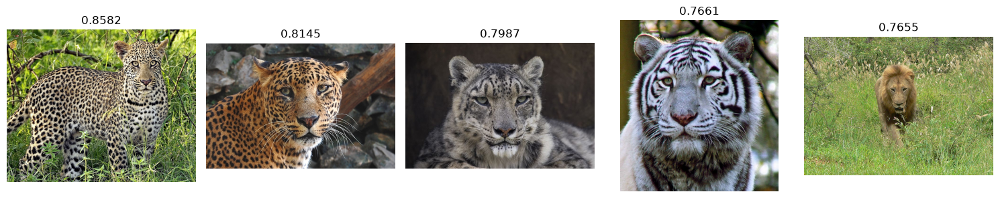

In [15]:
task3("im240.jpg", 5, "OpenCLIP-Fused-512")

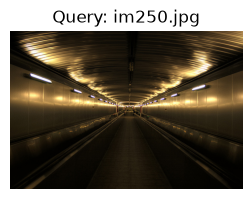

Model: OpenCLIP-Fused-512 (similarity)
Top 5 results:

  1. im13403.jpg — similarity: 0.8442
  2. im20908.jpg — similarity: 0.8402
  3. im14809.jpg — similarity: 0.8298
  4. im6200.jpg — similarity: 0.8233
  5. im2572.jpg — similarity: 0.8175


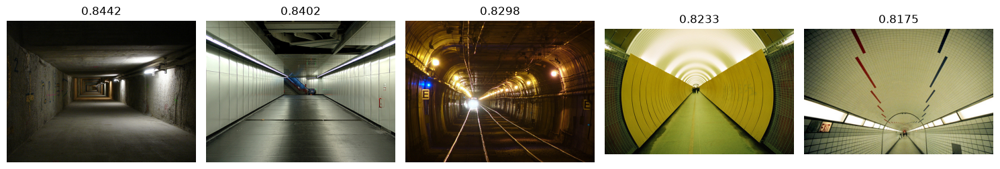

In [15]:
task3("im250.jpg", 5, "OpenCLIP-Fused-512")

## 4 — Query by Tag (Text-to-Image Retrieval)

Given a text query and a value k, find the k most similar images — using only the OpenCLIP models (MPEG-7 descriptors are purely visual, no text counterpart).

The text query gets encoded through CLIP's text encoder into the same 512-d space, then we rank all images by cosine similarity.

In [13]:
CLIP_MODELS = {
    "OpenCLIP-Image-512": clip_image_features,
    "OpenCLIP-TagText-512": clip_tag_features,
    "OpenCLIP-AnnotationText-512": clip_ann_features,
    "OpenCLIP-Fused-512": clip_fused_features,
}

def find_k_nearest_by_tag(tag, k, model_name):
    tokens = tokenizer([tag]).to(device)
    with torch.no_grad():
        query_vec = model.encode_text(tokens)
    query_vec = query_vec / query_vec.norm(dim=-1, keepdim=True)
    query_vec = query_vec.cpu().numpy().flatten()

    features = CLIP_MODELS[model_name]

    scores = []
    for i in range(len(features)):
        score = cosine_similarity(query_vec, features[i])
        scores.append((i, score))

    scores.sort(key=lambda x: x[1], reverse=True)
    return scores[:k]

### Visualization
Same layout as Section 3, but starting from a text tag instead of an image.

In [14]:
def task4(tag, k, model_name):
    results = find_k_nearest_by_tag(tag, k, model_name)

    print(f'Query tag: "{tag}"')
    print(f"Model: {model_name}")
    print(f"Top {k} results:\n")

    fig, axes = plt.subplots(1, k, figsize=(3 * k, 3))
    if k == 1:
        axes = [axes]

    for idx, (img_index, score) in enumerate(results):
        filename = all_filenames[img_index]
        img = Image.open(os.path.join(IMAGE_DIR, filename))
        axes[idx].imshow(img)
        axes[idx].set_title(f"{score:.4f}")
        axes[idx].axis("off")
        print(f"  {idx+1}. {filename} — similarity: {score:.4f}")

    plt.tight_layout()
    plt.show()

Query tag: "cat"
Model: OpenCLIP-Image-512
Top 5 results:

  1. im1592.jpg — similarity: 0.3093
  2. im6430.jpg — similarity: 0.3049
  3. im4139.jpg — similarity: 0.3047
  4. im23373.jpg — similarity: 0.3047
  5. im11146.jpg — similarity: 0.3042


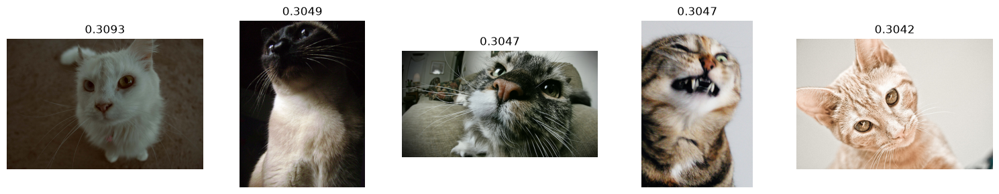

In [18]:
task4("cat", 5, "OpenCLIP-Image-512")

Query tag: "dog"
Model: OpenCLIP-Fused-512
Top 5 results:

  1. im5117.jpg — similarity: 0.7246
  2. im1291.jpg — similarity: 0.6789
  3. im11390.jpg — similarity: 0.6705
  4. im3563.jpg — similarity: 0.6693
  5. im7851.jpg — similarity: 0.6673


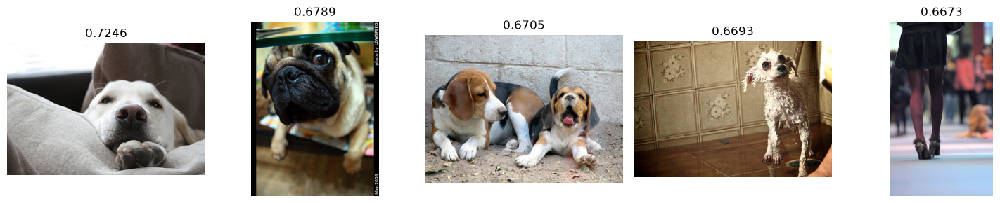

In [19]:
task4("dog", 5, "OpenCLIP-Fused-512")

Query tag: "dog"
Model: OpenCLIP-TagText-512
Top 5 results:

  1. im2508.jpg — similarity: 0.8668
  2. im3563.jpg — similarity: 0.8595
  3. im23934.jpg — similarity: 0.8589
  4. im11159.jpg — similarity: 0.8538
  5. im1368.jpg — similarity: 0.8497


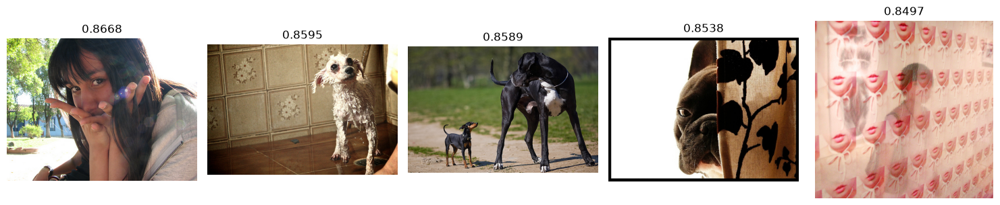

In [20]:
task4("dog", 5, "OpenCLIP-TagText-512")

Query tag: "sky"
Model: OpenCLIP-AnnotationText-512
Top 5 results:

  1. im131.jpg — similarity: 1.0000
  2. im617.jpg — similarity: 1.0000
  3. im622.jpg — similarity: 1.0000
  4. im986.jpg — similarity: 1.0000
  5. im1417.jpg — similarity: 1.0000


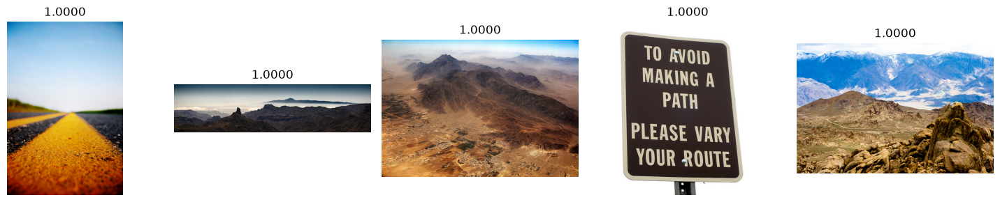

In [34]:
task4("sky", 5, "OpenCLIP-AnnotationText-512")

Query tag: "night"
Model: OpenCLIP-AnnotationText-512
Top 5 results:

  1. im88.jpg — similarity: 1.0000
  2. im225.jpg — similarity: 1.0000
  3. im299.jpg — similarity: 1.0000
  4. im377.jpg — similarity: 1.0000
  5. im419.jpg — similarity: 1.0000


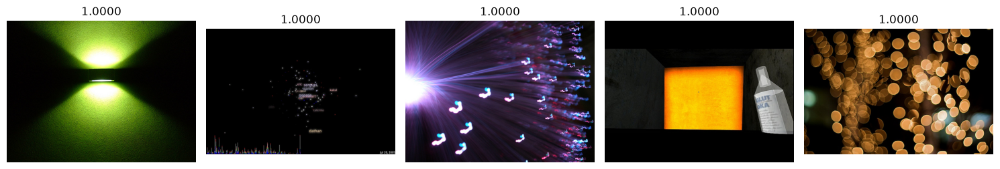

In [21]:
task4("night", 5, "OpenCLIP-AnnotationText-512")

## 5 — Hybrid Feature Spaces (PCA & SVD Fusion)

### 5a — PCA-Fused (705-d → 512-d)

Concatenate Edge Histogram (150-d) + Homogeneous Texture (43-d) + OpenCLIP-Fused (512-d) into a single 705-d vector per image, then reduce to 512-d with PCA.

This combines the complementary information from hand-crafted and learned features into one compact representation.

In [15]:
# Concatenate: Edge Histogram (150) + Homogeneous Texture (43) + OpenCLIP-Fused (512) = 705-d
concat_features = np.hstack([eh_features, ht_features, clip_fused_features])
print(f"Concatenated features: {concat_features.shape}")

# Center the data
pca_mean = concat_features.mean(axis=0)
centered = concat_features - pca_mean

# Covariance matrix + eigendecomposition
cov_matrix = np.cov(centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort by eigenvalue descending (eigh returns ascending)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Keep top 512 eigenvectors and project
k = 512
pca_components = eigenvectors[:, :k]
mir_pca_fused = centered @ pca_components
print(f"PCA-Fused: {mir_pca_fused.shape}")

np.save(os.path.join(FEATURES_DIR, "MIR-OpenClip-PCAFused-512.npy"), mir_pca_fused)
with open(os.path.join(FEATURES_DIR, "pca_model.pkl"), "wb") as f:
    pickle.dump({"mean": pca_mean, "components": pca_components, "eigenvalues": eigenvalues[:k]}, f)
print("PCA model saved.")

variance_explained = eigenvalues[:k].sum() / eigenvalues.sum()
print(f"Variance explained by 512 components: {variance_explained:.4f}")

Concatenated features: (25000, 705)
PCA-Fused: (25000, 512)
PCA model saved.
Variance explained by 512 components: 0.9949


### 5b — SVD-Fused (705-d → 512-d)

Same concatenated input, different decomposition — SVD on the raw (uncentered) data matrix. Truncating to the top 512 singular vectors gives the reduced representation.

In [16]:
# SVD on the raw (uncentered) concatenated data
U, S, Vt = np.linalg.svd(concat_features, full_matrices=False)
print(f"U: {U.shape}, S: {S.shape}, Vt: {Vt.shape}")

# Truncate to top 512
k = 512
U_k = U[:, :k]
S_k = S[:k]
Vt_k = Vt[:k, :]

# Reduced representation: U_k scaled by singular values
mir_svd_fused = U_k * S_k
print(f"SVD-Fused: {mir_svd_fused.shape}")

np.save(os.path.join(FEATURES_DIR, "MIR-OpenClip-SVDFused-512.npy"), mir_svd_fused)
with open(os.path.join(FEATURES_DIR, "svd_model.pkl"), "wb") as f:
    pickle.dump({"components": Vt_k, "singular_values": S_k}, f)
print("SVD model saved.")

energy_retained = (S_k ** 2).sum() / (S ** 2).sum()
print(f"Energy retained by 512 components: {energy_retained:.4f}")

U: (25000, 705), S: (705,), Vt: (705, 705)
SVD-Fused: (25000, 512)
SVD model saved.
Energy retained by 512 components: 0.9997


### 5c — All 8 feature spaces consolidated

Every image is now represented in 8 different vector spaces: the original six + PCA-fused + SVD-fused.

In [17]:
mir_pca_fused = np.load(os.path.join(FEATURES_DIR, "MIR-OpenClip-PCAFused-512.npy"))
mir_svd_fused = np.load(os.path.join(FEATURES_DIR, "MIR-OpenClip-SVDFused-512.npy"))

ALL_FEATURE_SPACES = {
    "MIRFLICKR-EdgeHistogram-150": eh_features,
    "MIRFLICKR-HomogeneousTexture": ht_features,
    "OpenCLIP-Image-512": clip_image_features,
    "OpenCLIP-TagText-512": clip_tag_features,
    "OpenCLIP-AnnotationText-512": clip_ann_features,
    "OpenCLIP-Fused-512": clip_fused_features,
    "MIR-OpenClip-PCAFused-512": mir_pca_fused,
    "MIR-OpenClip-SVDFused-512": mir_svd_fused,
}

for name, matrix in ALL_FEATURE_SPACES.items():
    print(f"{name}: {matrix.shape}")

with open(os.path.join(FEATURES_DIR, "metadata.pkl"), "wb") as f:
    pickle.dump({
        "filenames": all_filenames,
        "tags": all_tags,
        "annotations": all_annotations,
    }, f)

print("\nAll 8 feature spaces ready.")

MIRFLICKR-EdgeHistogram-150: (25000, 150)
MIRFLICKR-HomogeneousTexture: (25000, 43)
OpenCLIP-Image-512: (25000, 512)
OpenCLIP-TagText-512: (25000, 512)
OpenCLIP-AnnotationText-512: (25000, 512)
OpenCLIP-Fused-512: (25000, 512)
MIR-OpenClip-PCAFused-512: (25000, 512)
MIR-OpenClip-SVDFused-512: (25000, 512)

All 8 feature spaces ready. Metadata confirmed shared and saved.


### 5d — Unified k-NN across all 8 spaces

Generalized retrieval that works with any of the 8 feature spaces and also accepts external (non-dataset) images for the CLIP-based spaces.

In [18]:
with open(os.path.join(FEATURES_DIR, "pca_model.pkl"), "rb") as f:
    pca_model = pickle.load(f)
with open(os.path.join(FEATURES_DIR, "svd_model.pkl"), "rb") as f:
    svd_model = pickle.load(f)

def get_vector_for_image(img_path_or_filename, space_name, k_dim=512):
    """Return the feature vector for an image in the chosen space.
    Dataset images use precomputed lookup; external images get live CLIP extraction."""

    is_dataset_image = img_path_or_filename in all_filenames

    # MPEG-7-dependent spaces only work for dataset images
    if space_name in ("MIRFLICKR-EdgeHistogram-150", "MIRFLICKR-HomogeneousTexture",
                       "MIR-OpenClip-PCAFused-512", "MIR-OpenClip-SVDFused-512"):
        if not is_dataset_image:
            raise ValueError(f"'{space_name}' requires pre-computed MPEG-7 descriptors (dataset images only).")
        img_number = int(img_path_or_filename.replace("im", "").replace(".jpg", ""))
        if space_name == "MIR-OpenClip-PCAFused-512":
            raw_vec = np.concatenate([eh_features[img_number-1], ht_features[img_number-1], clip_fused_features[img_number-1]])
            return (raw_vec - pca_model["mean"]) @ pca_model["components"]
        elif space_name == "MIR-OpenClip-SVDFused-512":
            raw_vec = np.concatenate([eh_features[img_number-1], ht_features[img_number-1], clip_fused_features[img_number-1]])
            return raw_vec @ svd_model["components"].T
        else:
            return ALL_FEATURE_SPACES[space_name][img_number - 1]

    # CLIP spaces: dataset lookup or live extraction
    else:
        if is_dataset_image:
            img_number = int(img_path_or_filename.replace("im", "").replace(".jpg", ""))
            return ALL_FEATURE_SPACES[space_name][img_number - 1]
        else:
            img = Image.open(img_path_or_filename).convert("RGB")
            img_tensor = preprocess(img).unsqueeze(0).to(device)
            with torch.no_grad():
                img_vec = model.encode_image(img_tensor)
            img_vec = (img_vec / img_vec.norm(dim=-1, keepdim=True)).cpu().numpy().flatten()

            if space_name == "OpenCLIP-Image-512":
                return img_vec
            else:
                return img_vec

### 5d — Search and visualization
Same pattern as Section 3, but using `get_vector_for_image` so it works across all 8 spaces.

In [19]:
SPACE_MEASURES = {
    "MIRFLICKR-EdgeHistogram-150": euclidean_distance,
    "MIRFLICKR-HomogeneousTexture": euclidean_distance,
    "OpenCLIP-Image-512": cosine_similarity,
    "OpenCLIP-TagText-512": cosine_similarity,
    "OpenCLIP-AnnotationText-512": cosine_similarity,
    "OpenCLIP-Fused-512": cosine_similarity,
    "MIR-OpenClip-PCAFused-512": cosine_similarity,
    "MIR-OpenClip-SVDFused-512": cosine_similarity,
}
SPACE_MEASURE_TYPE = {name: ("distance" if fn is euclidean_distance else "similarity")
                       for name, fn in SPACE_MEASURES.items()}

def find_k_nearest_task5d(img_path_or_filename, k, space_name):
    query_vec = get_vector_for_image(img_path_or_filename, space_name)
    measure_fn = SPACE_MEASURES[space_name]
    measure_type = SPACE_MEASURE_TYPE[space_name]
    features = ALL_FEATURE_SPACES[space_name]

    query_index = all_filenames.index(img_path_or_filename) if img_path_or_filename in all_filenames else None

    scores = []
    for i in range(len(features)):
        if i == query_index:
            continue
        score = measure_fn(query_vec, features[i])
        scores.append((i, score))

    scores.sort(key=lambda x: x[1], reverse=(measure_type == "similarity"))
    return scores[:k], measure_type


def task5d(img_path_or_filename, k, space_name):
    results, measure_type = find_k_nearest_task5d(img_path_or_filename, k, space_name)

    if img_path_or_filename in all_filenames:
        query_img = Image.open(os.path.join(IMAGE_DIR, img_path_or_filename))
    else:
        query_img = Image.open(img_path_or_filename)

    plt.figure(figsize=(3, 3))
    plt.imshow(query_img)
    plt.title(f"Query: {img_path_or_filename}")
    plt.axis("off")
    plt.show()

    print(f"Feature space: {space_name} ({measure_type})")
    print(f"Top {k} results:\n")

    fig, axes = plt.subplots(1, k, figsize=(3 * k, 3))
    if k == 1:
        axes = [axes]

    for idx, (img_index, score) in enumerate(results):
        filename = all_filenames[img_index]
        img = Image.open(os.path.join(IMAGE_DIR, filename))
        axes[idx].imshow(img)
        axes[idx].set_title(f"{score:.4f}")
        axes[idx].axis("off")
        print(f"  {idx+1}. {filename} — {measure_type}: {score:.4f}")

    plt.tight_layout()
    plt.show()

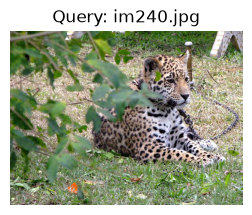

Feature space: OpenCLIP-Fused-512 (similarity)
Top 5 results:

  1. im3464.jpg — similarity: 0.8582
  2. im24830.jpg — similarity: 0.8145
  3. im15462.jpg — similarity: 0.7987
  4. im24995.jpg — similarity: 0.7661
  5. im8410.jpg — similarity: 0.7655


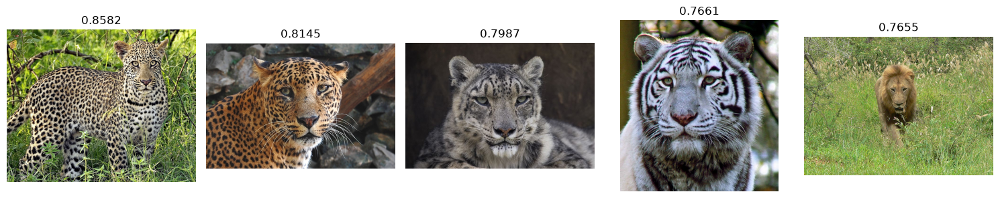

In [20]:
task5d("im240.jpg", 5, "OpenCLIP-Fused-512")

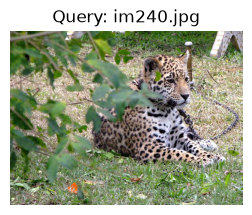

Feature space: MIR-OpenClip-PCAFused-512 (similarity)
Top 5 results:

  1. im3464.jpg — similarity: 0.9316
  2. im2836.jpg — similarity: 0.8897
  3. im22976.jpg — similarity: 0.8820
  4. im8410.jpg — similarity: 0.8810
  5. im13682.jpg — similarity: 0.8773


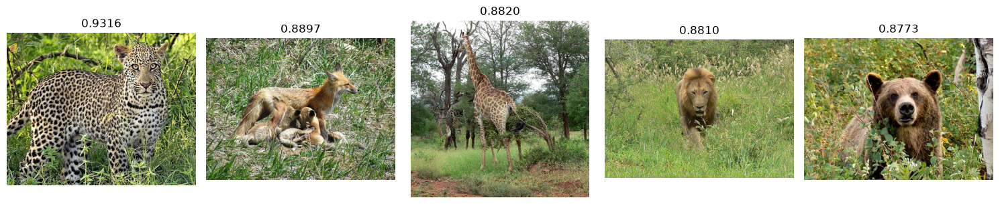

In [28]:
task5d("im240.jpg", 5, "MIR-OpenClip-PCAFused-512")

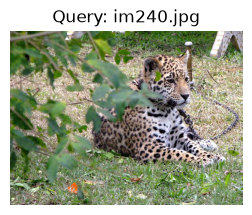

Feature space: MIR-OpenClip-SVDFused-512 (similarity)
Top 5 results:

  1. im3464.jpg — similarity: 0.9952
  2. im13682.jpg — similarity: 0.9914
  3. im1324.jpg — similarity: 0.9911
  4. im22976.jpg — similarity: 0.9909
  5. im23471.jpg — similarity: 0.9908


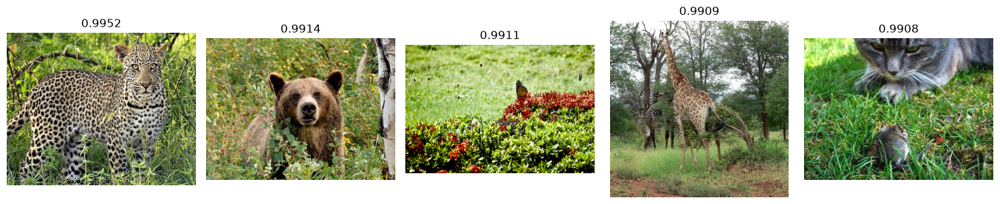

In [29]:
task5d("im240.jpg", 5, "MIR-OpenClip-SVDFused-512")

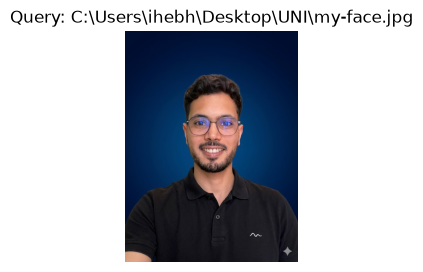

Feature space: OpenCLIP-Image-512 (similarity)
Top 5 results:

  1. im450.jpg — similarity: 0.6549
  2. im10807.jpg — similarity: 0.6084
  3. im9954.jpg — similarity: 0.5823
  4. im14520.jpg — similarity: 0.5578
  5. im23492.jpg — similarity: 0.5537


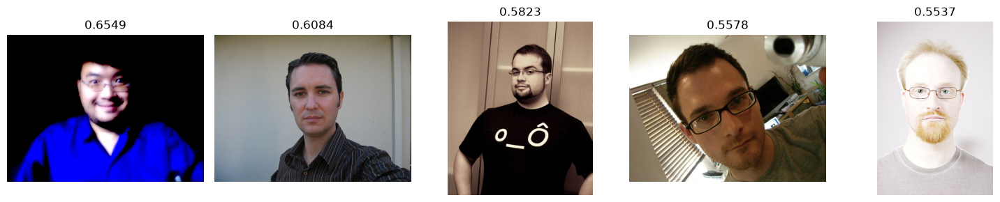

In [24]:
task5d(r"C:\Users\ihebh\Desktop\UNI\my-face.jpg", 5, "OpenCLIP-Image-512")

## 6 — Inherent Dimensionality

For each feature space, we compute how many dimensions are actually needed to capture 95% of the variance — the gap between nominal and inherent dimensionality tells us how much redundancy each representation carries.

In [21]:
def inherent_dimensionality(data_matrix, variance_threshold=0.95):
    """Number of components needed to explain the given fraction of total variance."""
    mean = data_matrix.mean(axis=0)
    centered = data_matrix - mean
    cov_matrix = np.cov(centered, rowvar=False)

    eigenvalues = np.linalg.eigvalsh(cov_matrix)
    eigenvalues = np.sort(eigenvalues)[::-1]
    eigenvalues = np.clip(eigenvalues, a_min=0, a_max=None)

    total_variance = eigenvalues.sum()
    cumulative_variance = np.cumsum(eigenvalues) / total_variance

    n_components = np.searchsorted(cumulative_variance, variance_threshold) + 1
    return n_components


for space_name, matrix in ALL_FEATURE_SPACES.items():
    n_dims = inherent_dimensionality(matrix)
    nominal_dims = matrix.shape[1]
    print(f"{space_name:40s}  nominal: {nominal_dims:4d}  ->  inherent (95% var): {n_dims:4d}")

MIRFLICKR-EdgeHistogram-150               nominal:  150  ->  inherent (95% variance):   33
MIRFLICKR-HomogeneousTexture              nominal:   43  ->  inherent (95% variance):    6
OpenCLIP-Image-512                        nominal:  512  ->  inherent (95% variance):  321
OpenCLIP-TagText-512                      nominal:  512  ->  inherent (95% variance):  369
OpenCLIP-AnnotationText-512               nominal:  512  ->  inherent (95% variance):   36
OpenCLIP-Fused-512                        nominal:  512  ->  inherent (95% variance):  337
MIR-OpenClip-PCAFused-512                 nominal:  512  ->  inherent (95% variance):  226
MIR-OpenClip-SVDFused-512                 nominal:  512  ->  inherent (95% variance):  226


## 7 — Clustering (DBSCAN & Spectral)

Two clustering approaches, both implemented from scratch:

- **DBSCAN** (density-based): discovers clusters as dense regions, finds the number of clusters automatically, and labels outliers as noise.
- **Spectral Clustering** (graph-based): builds a similarity graph, analyzes the Laplacian eigenvectors, and uses K-means in eigenspace to partition the data.

Both are evaluated with compactness, separation, expansion, modularity, and silhouette scores, plus t-SNE visualizations.

### 7a — DBSCAN (from scratch)

Density-based clustering — no predefined cluster count. Core points (≥ MinPts neighbors within ε), border points, and noise are identified by expanding density-reachable chains.

In [22]:
from sklearn.manifold import TSNE

def dbscan(features, eps, min_pts):
    n = len(features)

    # Pairwise cosine distance
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    norms[norms == 0] = 1
    dist = 1 - (features / norms) @ (features / norms).T

    UNVISITED, NOISE = 0, -1
    labels = np.full(n, UNVISITED)
    cluster_id = 0

    for i in range(n):
        if labels[i] != UNVISITED: continue

        neighbors = set(np.where(dist[i] <= eps)[0].tolist())

        if len(neighbors) < min_pts:
            labels[i] = NOISE
            continue

        # Core point — start new cluster and expand
        labels[i] = cluster_id
        seeds = neighbors - {i}

        while seeds:
            q = seeds.pop()
            if labels[q] == NOISE:
                labels[q] = cluster_id
            if labels[q] != UNVISITED:
                continue
            labels[q] = cluster_id

            q_neighbors = set(np.where(dist[q] <= eps)[0].tolist())
            if len(q_neighbors) >= min_pts:
                seeds |= q_neighbors

        cluster_id += 1

    return labels

### 7b — Spectral Clustering (from scratch)

Graph-based approach: cosine similarity matrix → normalized Laplacian → eigendecompose → K-means on the smallest eigenvectors (Ng-Jordan-Weiss).

In [23]:
def kmeans_scratch(X, k, max_iter=100):
    n = X.shape[0]

    # Max-a-min initialization
    centers = [X[np.random.randint(n)]]
    for _ in range(1, k):
        dists = np.array([min(np.linalg.norm(x - c) for c in centers) for x in X])
        centers.append(X[np.argmax(dists)])
    centers = np.array(centers)

    for _ in range(max_iter):
        dists = np.linalg.norm(X[:, None] - centers[None, :], axis=2)
        labels = np.argmin(dists, axis=1)
        new_centers = np.array([X[labels == j].mean(axis=0)
                                if (labels == j).any() else centers[j] for j in range(k)])
        if np.allclose(new_centers, centers): break
        centers = new_centers
    return labels


def spectral_clustering(features, c):
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    norms[norms == 0] = 1
    normed = features / norms

    # Cosine similarity graph
    A = normed @ normed.T
    np.fill_diagonal(A, 0)
    A = np.clip(A, 0, None)

    # Normalized Laplacian
    degrees = A.sum(axis=1)
    degrees[degrees == 0] = 1
    D_inv_sqrt = np.diag(1.0 / np.sqrt(degrees))
    L_norm = D_inv_sqrt @ (np.diag(degrees) - A) @ D_inv_sqrt

    # Smallest c eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(L_norm)
    U = eigenvectors[:, :c]

    # Row-normalize (NJW) then K-means
    row_norms = np.linalg.norm(U, axis=1, keepdims=True)
    row_norms[row_norms == 0] = 1
    Y = U / row_norms

    return kmeans_scratch(Y, c)

### Quality measures
Five measures: **Compactness** (intra-cluster similarity), **Separation** (inter-cluster distance), **Expansion** (cross-boundary edges), **Modularity** (structure vs. random), **Silhouette** (per-point cluster fit, range [-1, 1]).

In [24]:
def compute_quality_measures(features, labels):
    unique_labels = np.unique(labels)
    n = len(labels)
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    norms[norms == 0] = 1
    sim = (features / norms) @ (features / norms).T
    dist = 1 - sim
    SIM_T = 0.5
    clusters = {l: np.where(labels == l)[0] for l in unique_labels}

    # Compactness
    comp = []
    for m in clusters.values():
        if len(m) < 2: comp.append(1.0); continue
        s = sim[np.ix_(m, m)]
        comp.append(np.triu(s, k=1).sum() / (len(m) * (len(m) - 1) / 2))

    # Separation
    sep = []
    for li in unique_labels:
        for lj in unique_labels:
            if li >= lj: continue
            sep.append(dist[np.ix_(clusters[li], clusters[lj])].min())

    # Expansion
    exp = []
    for li in unique_labels:
        for lj in unique_labels:
            if li >= lj: continue
            cut = np.sum(sim[np.ix_(clusters[li], clusters[lj])] > SIM_T)
            exp.append(cut / min(len(clusters[li]), len(clusters[lj])))

    # Modularity
    total_edges = max(np.sum(sim > SIM_T) / 2, 1)
    modularity = 0.0
    for m in clusters.values():
        e_in = np.sum(sim[np.ix_(m, m)] > SIM_T) / 2
        deg = np.sum(sim[m] > SIM_T)
        modularity += (e_in / total_edges) - (deg / (2 * total_edges)) ** 2

    # Silhouette
    sil = []
    for i in range(n):
        own = clusters[labels[i]]
        own_no_self = own[own != i]
        if len(own_no_self) == 0: sil.append(0.0); continue
        a = dist[i, own_no_self].mean()
        b = min(dist[i, clusters[l]].mean() for l in unique_labels if l != labels[i])
        sil.append((b - a) / max(a, b) if max(a, b) > 0 else 0.0)

    print(f"\n  Compactness:  {np.mean(comp):.4f}    Separation: {np.mean(sep) if sep else 0:.4f}")
    print(f"  Expansion:    {np.mean(exp) if exp else 0:.4f}    Modularity: {modularity:.4f}")
    print(f"  Silhouette:   {np.mean(sil):.4f}")

### Run DBSCAN
DBSCAN on a sampled subset → keep the c largest clusters → quality measures → t-SNE visualization.

In [25]:
def task7a(space_name, c, eps=0.3, min_pts=5, indices=None):
    features = ALL_FEATURE_SPACES[space_name]
    fnames = list(all_filenames)
    if indices is not None:
        features = features[indices]
        fnames = [all_filenames[i] for i in indices]

    print(f"DBSCAN on '{space_name}': {len(features)} vectors, eps={eps}, min_pts={min_pts}")
    labels = dbscan(features, eps, min_pts)

    # Keep only the c largest clusters, rest → noise
    real = sorted([(l, np.sum(labels == l)) for l in np.unique(labels) if l >= 0],
                  key=lambda x: x[1], reverse=True)[:c]
    keep = {l for l, _ in real}
    labels = np.where(np.isin(labels, list(keep)), labels, -1)
    print(f"Noise: {np.sum(labels == -1)} points")
    for l, s in real: print(f"  Cluster {l}: {s} images")

    non_noise = labels >= 0
    if non_noise.sum() >= 2:
        compute_quality_measures(features[non_noise], labels[non_noise])

    # t-SNE
    coords = TSNE(n_components=2, random_state=42,
                  perplexity=min(30, len(features)-1)).fit_transform(features)
    plt.figure(figsize=(9, 6))
    noise_mask = labels == -1
    if noise_mask.any():
        plt.scatter(coords[noise_mask, 0], coords[noise_mask, 1],
                    c='gray', alpha=0.15, s=8, label=f"Noise ({noise_mask.sum()})")
    for l, s in real:
        mask = labels == l
        plt.scatter(coords[mask, 0], coords[mask, 1], label=f"C{l} ({s})", alpha=0.6, s=15)
    plt.title(f"DBSCAN — eps={eps}, min_pts={min_pts}"); plt.legend(); plt.axis("off"); plt.show()

    # Thumbnails
    for l, s in real:
        members = np.where(labels == l)[0][:8]
        fig, axes = plt.subplots(1, len(members), figsize=(2.5*len(members), 2.5))
        if len(members) == 1: axes = [axes]
        fig.suptitle(f"Cluster {l} — {s} images", fontsize=11)
        for ax, idx in zip(axes, members):
            ax.imshow(Image.open(os.path.join(IMAGE_DIR, fnames[idx])))
            ax.set_title(fnames[idx], fontsize=7); ax.axis("off")
        plt.tight_layout(); plt.show()

In [31]:
sample_idx = np.random.choice(N_IMAGES, 2000, replace=False)
task7a("OpenCLIP-Fused-512", c=3, eps=0.3, min_pts=5, indices=sample_idx)

DBSCAN on 'OpenCLIP-Fused-512': 2000 vectors, eps=0.3, min_pts=5


KeyboardInterrupt: 

### Run Spectral Clustering
Filter images by a tag → spectral clustering into c groups → quality measures → t-SNE → sample thumbnails.

In [26]:
def task7b(space_name, tag, c):
    indices = [i for i, tags in enumerate(all_tags) if tag in tags]
    if len(indices) < c:
        print(f"Tag '{tag}': only {len(indices)} images, need at least {c}."); return
    features = ALL_FEATURE_SPACES[space_name][indices]
    filenames = [all_filenames[i] for i in indices]
    print(f"Tag '{tag}': {len(indices)} images → {c} clusters in '{space_name}'")

    labels = spectral_clustering(features, c)
    for l in np.unique(labels): print(f"  Cluster {l}: {np.sum(labels == l)} images")
    compute_quality_measures(features, labels)

    # t-SNE
    coords = TSNE(n_components=2, random_state=42,
                  perplexity=min(30, len(features)-1)).fit_transform(features)
    plt.figure(figsize=(9, 6))
    for l in np.unique(labels):
        mask = labels == l
        plt.scatter(coords[mask, 0], coords[mask, 1], label=f"C{l} ({mask.sum()})", alpha=0.6, s=15)
    plt.title(f"Spectral — '{tag}', {c} clusters"); plt.legend(); plt.axis("off"); plt.show()

    # Thumbnails
    for l in np.unique(labels):
        members = np.where(labels == l)[0][:8]
        fig, axes = plt.subplots(1, len(members), figsize=(2.5*len(members), 2.5))
        if len(members) == 1: axes = [axes]
        fig.suptitle(f"Cluster {l} — {np.sum(labels==l)} images", fontsize=11)
        for ax, idx in zip(axes, members):
            ax.imshow(Image.open(os.path.join(IMAGE_DIR, filenames[idx])))
            ax.set_title(filenames[idx], fontsize=7); ax.axis("off")
        plt.tight_layout(); plt.show()

Tag 'sky': 845 images → 3 clusters in 'OpenCLIP-Fused-512'
  Cluster 0: 272 images
  Cluster 1: 269 images
  Cluster 2: 304 images

  Compactness:  0.5538    Separation: 0.0862
  Expansion:    125.0898    Modularity: 0.1020
  Silhouette:   0.1031



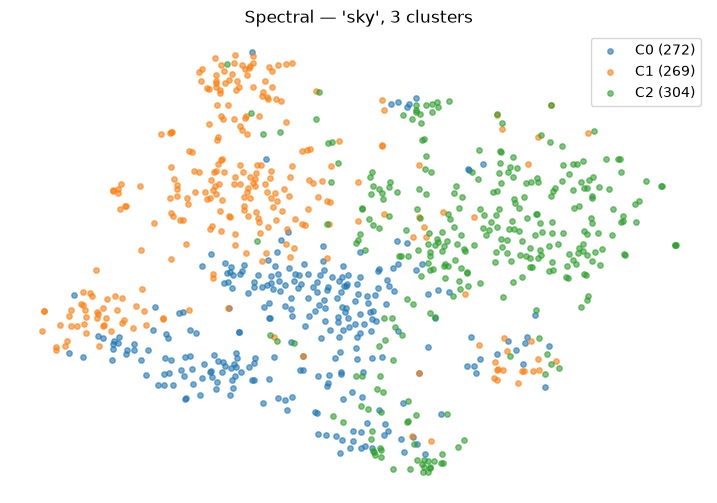

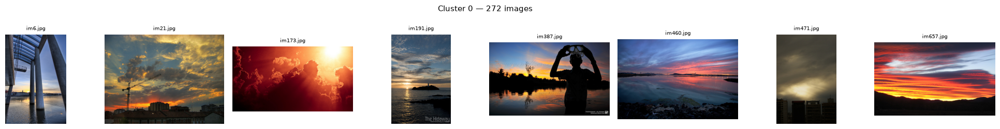

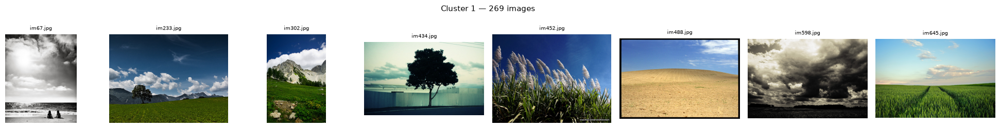

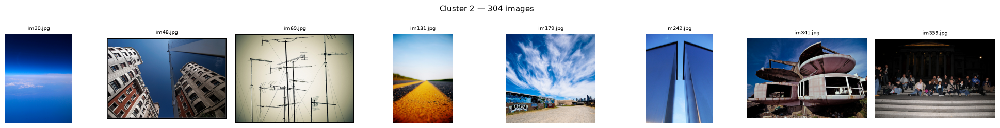

In [27]:
task7b("OpenCLIP-Fused-512", "sky", 3)

## 8 — Tag Ranking

Two approaches to rank all tags in the corpus for a query image:
- **Decision Tree** (8a): partition the feature space with information-gain splits, rank tags by frequency at the matching leaf.
- **Cosine Similarity** (8b): encode the query image and every unique tag into CLIP's shared space, rank by dot product.

### 8a — Decision Tree (from scratch)

Entropy-based information gain for splitting. At query time, traverse root → leaf, then rank tags by how often they appear among the training images at that leaf.

Overfitting control: max depth + minimum leaf size.

In [28]:
def entropy(labels_list):
    """Shannon entropy over tag frequency distribution."""
    tag_counts = {}
    total = len(labels_list)
    if total == 0: return 0.0
    for tags in labels_list:
        for t in tags:
            tag_counts[t] = tag_counts.get(t, 0) + 1
    probs = np.array(list(tag_counts.values())) / total
    return -np.sum(probs * np.log2(probs + 1e-12))


class DecisionTreeNode:
    def __init__(self, indices=None, tag_ranking=None,
                 feature_idx=None, threshold=None, left=None, right=None):
        self.indices = indices
        self.tag_ranking = tag_ranking
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.left = left
        self.right = right

    def is_leaf(self):
        return self.tag_ranking is not None


def build_decision_tree(features, tags_list, indices, max_depth=10, min_leaf=20, n_candidates=50):

    def rank_tags(idxs):
        counts = {}
        for i in idxs:
            for t in tags_list[i]:
                counts[t] = counts.get(t, 0) + 1
        return sorted(counts.items(), key=lambda x: x[1], reverse=True)

    def build(idxs, depth):
        if depth >= max_depth or len(idxs) < min_leaf:
            return DecisionTreeNode(indices=idxs, tag_ranking=rank_tags(idxs))

        current_tags = [tags_list[i] for i in idxs]
        current_ent = entropy(current_tags)
        if current_ent == 0:
            return DecisionTreeNode(indices=idxs, tag_ranking=rank_tags(idxs))

        best_gain, best_feat, best_thresh = 0, None, None
        best_left, best_right = None, None

        # Random subset of feature dims (faster + reduces overfitting)
        candidates = np.random.choice(features.shape[1],
                                      min(n_candidates, features.shape[1]), replace=False)
        for f in candidates:
            values = features[idxs, f]
            thresh = np.median(values)
            left_idx = [idxs[j] for j in range(len(idxs)) if values[j] <= thresh]
            right_idx = [idxs[j] for j in range(len(idxs)) if values[j] > thresh]

            if not left_idx or not right_idx:
                continue

            left_ent = entropy([tags_list[i] for i in left_idx])
            right_ent = entropy([tags_list[i] for i in right_idx])
            gain = current_ent - (len(left_idx)/len(idxs)) * left_ent - (len(right_idx)/len(idxs)) * right_ent

            if gain > best_gain:
                best_gain = gain
                best_feat = f
                best_thresh = thresh
                best_left = left_idx
                best_right = right_idx

        if best_feat is None:
            return DecisionTreeNode(indices=idxs, tag_ranking=rank_tags(idxs))

        return DecisionTreeNode(
            feature_idx=best_feat,
            threshold=best_thresh,
            left=build(best_left, depth + 1),
            right=build(best_right, depth + 1)
        )

    return build(list(indices), 0)


def predict_tags(tree, query_vec):
    node = tree
    while not node.is_leaf():
        if query_vec[node.feature_idx] <= node.threshold:
            node = node.left
        else:
            node = node.right
    return node.tag_ranking

### 8a — Results

In [29]:
def task8a(img_filename, space_name, top_k=10):
    print(f"Building decision tree on '{space_name}'...")
    features = ALL_FEATURE_SPACES[space_name]
    tree = build_decision_tree(features, all_tags, range(N_IMAGES))

    query_vec = get_vector_for_image(img_filename, space_name)
    ranking = predict_tags(tree, query_vec)

    if img_filename in all_filenames:
        img = Image.open(os.path.join(IMAGE_DIR, img_filename))
    else:
        img = Image.open(img_filename)
    plt.figure(figsize=(3, 3))
    plt.imshow(img); plt.title(f"Query: {img_filename}"); plt.axis("off"); plt.show()

    print(f"\nTop {top_k} tags (decision tree, {space_name}):")
    for i, (tag, count) in enumerate(ranking[:top_k]):
        print(f"  {i+1}. {tag:20s}  (frequency: {count})")

Building decision tree on 'MIR-OpenClip-PCAFused-512'...


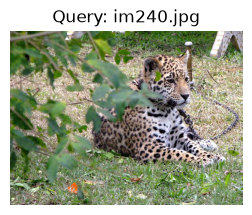


Top 10 tags (decision tree, MIR-OpenClip-PCAFused-512):
  1. zoo                   (frequency: 5)
  2. animal                (frequency: 4)
  3. water                 (frequency: 4)
  4. explore               (frequency: 2)
  5. hawaii                (frequency: 2)
  6. bigisland             (frequency: 2)
  7. jumping               (frequency: 2)
  8. milan                 (frequency: 2)
  9. milano                (frequency: 2)
  10. italy                 (frequency: 2)


In [30]:
task8a("im240.jpg", "MIR-OpenClip-PCAFused-512")


### 8b — Cosine-based tag ranking

No training needed — just geometry in the shared CLIP space. Encode every unique tag (~69K), compute cosine similarity against the query image vector, sort descending. This is essentially the inverse of Section 4 (text-to-image → image-to-text).

In [31]:
def rank_tags_cosine(img_filename, model_name, batch_size=512):
    img_number = int(img_filename.replace("im", "").replace(".jpg", ""))
    query_vec = ALL_FEATURE_SPACES[model_name][img_number - 1]

    unique_tags = sorted(set(t for tags in all_tags for t in tags))
    print(f"Encoding {len(unique_tags)} unique tags...")

    tag_vectors = np.zeros((len(unique_tags), 512), dtype=np.float32)
    for start in range(0, len(unique_tags), batch_size):
        batch = unique_tags[start:start + batch_size]
        tokens = tokenizer(batch).to(device)
        with torch.no_grad():
            vecs = model.encode_text(tokens)
        vecs = (vecs / vecs.norm(dim=-1, keepdim=True)).cpu().numpy()
        tag_vectors[start:start + len(batch)] = vecs

    scores = tag_vectors @ query_vec
    ranked = np.argsort(scores)[::-1]
    return [(unique_tags[i], scores[i]) for i in ranked]


def task8b(img_filename, model_name, top_k=10):
    ranking = rank_tags_cosine(img_filename, model_name)

    if img_filename in all_filenames:
        img = Image.open(os.path.join(IMAGE_DIR, img_filename))
    else:
        img = Image.open(img_filename)
    plt.figure(figsize=(3, 3))
    plt.imshow(img); plt.title(f"Query: {img_filename}"); plt.axis("off"); plt.show()

    print(f"\nTop {top_k} tags (cosine, {model_name}):")
    for i, (tag, score) in enumerate(ranking[:top_k]):
        print(f"  {i+1}. {tag:20s}  (similarity: {score:.4f})")

Encoding 69099 unique tags...


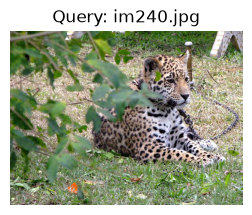


Top 10 tags (cosine, OpenCLIP-Fused-512):
  1. jaguarão              (similarity: 0.5983)
  2. leopard               (similarity: 0.5807)
  3. pantheratigrisaltaica  (similarity: 0.5770)
  4. jaguar                (similarity: 0.5719)
  5. animali               (similarity: 0.5698)
  6. jungla                (similarity: 0.5661)
  7. animales020708        (similarity: 0.5655)
  8. animales              (similarity: 0.5618)
  9. africaanimals         (similarity: 0.5572)
  10. cheetah               (similarity: 0.5559)


In [32]:
task8b("im240.jpg", "OpenCLIP-Fused-512")

## 9 — Locality Sensitive Hashing (LSH)

Approximate nearest-neighbor search for when brute-force k-NN doesn't scale. Uses SimHash (random hyperplane hashing) — similar vectors are more likely to land in the same bucket.

- **9a**: L hash tables × h random hyperplanes each → each vector gets an h-bit binary key per table.
- **9b**: Hash the query into all L tables → union candidate buckets → exact cosine only on candidates → return top k.

In [33]:
class LSHIndex:

    def __init__(self, L, h, features):
        self.L = L
        self.h = h
        self.features = features
        n, d = features.shape

        # L sets of h random hyperplanes
        self.hyperplanes = [np.random.randn(h, d) for _ in range(L)]

        # Hash every vector into all L tables
        self.tables = []
        for layer in range(L):
            table = {}
            projections = features @ self.hyperplanes[layer].T
            keys = (projections >= 0).astype(int)
            for i in range(n):
                key = tuple(keys[i])
                if key not in table: table[key] = []
                table[key].append(i)
            self.tables.append(table)

        print(f"LSH index: L={L} tables, h={h} bits/key, {n} vectors indexed.")

    def query(self, query_vec, k):
        candidate_set = set()
        overall_count = 0

        for layer in range(self.L):
            proj = query_vec @ self.hyperplanes[layer].T
            key = tuple((proj >= 0).astype(int))
            bucket = self.tables[layer].get(key, [])
            overall_count += len(bucket)
            candidate_set.update(bucket)

        unique_count = len(candidate_set)

        # Exact cosine on candidates only
        q_norm = query_vec / (np.linalg.norm(query_vec) + 1e-12)
        results = []
        for idx in candidate_set:
            v = self.features[idx]
            v_norm = v / (np.linalg.norm(v) + 1e-12)
            sim = np.dot(q_norm, v_norm)
            results.append((idx, sim))

        results.sort(key=lambda x: x[1], reverse=True)
        return results[:k], unique_count, overall_count

### Build index and query

In [34]:
def task9a(space_name, L, h):
    return LSHIndex(L, h, ALL_FEATURE_SPACES[space_name])


def task9b(index, img_filename, k, space_name):
    img_number = int(img_filename.replace("im", "").replace(".jpg", ""))
    query_vec = ALL_FEATURE_SPACES[space_name][img_number - 1]

    results, unique_cands, overall_cands = index.query(query_vec, k)

    img = Image.open(os.path.join(IMAGE_DIR, img_filename))
    plt.figure(figsize=(3, 3))
    plt.imshow(img); plt.title(f"Query: {img_filename}"); plt.axis("off"); plt.show()

    print(f"Candidates — unique: {unique_cands}, overall: {overall_cands}")
    print(f"Top {k} results:\n")

    fig, axes = plt.subplots(1, k, figsize=(3*k, 3))
    if k == 1: axes = [axes]
    for i, (img_idx, score) in enumerate(results):
        fname = all_filenames[img_idx]
        axes[i].imshow(Image.open(os.path.join(IMAGE_DIR, fname)))
        axes[i].set_title(f"{score:.4f}"); axes[i].axis("off")
        print(f"  {i+1}. {fname} — similarity: {score:.4f}")
    plt.tight_layout(); plt.show()

LSH index: L=10 tables, h=8 bits/key, 25000 vectors indexed.


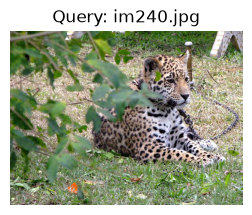

Candidates — unique: 3360, overall: 3602
Top 5 results:

  1. im240.jpg — similarity: 1.0000
  2. im3464.jpg — similarity: 0.8582
  3. im24830.jpg — similarity: 0.8145
  4. im15462.jpg — similarity: 0.7987
  5. im24995.jpg — similarity: 0.7661


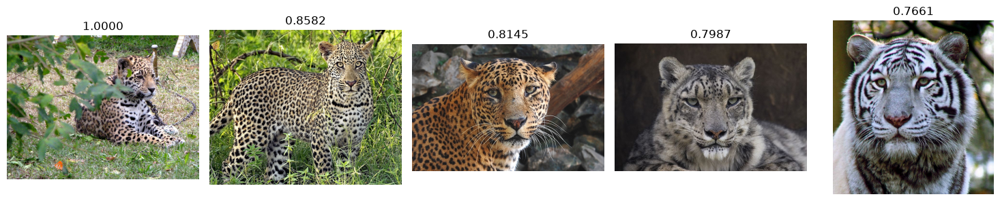

In [35]:
lsh_index = task9a("OpenCLIP-Fused-512", L=10, h=8)
task9b(lsh_index, "im240.jpg", 5, "OpenCLIP-Fused-512")

## Summary

This project explored the full image retrieval pipeline on 25K real-world images:

- **6 base feature spaces** (2 hand-crafted MPEG-7 + 4 learned OpenCLIP) plus **2 hybrid fused spaces** (PCA, SVD) — 8 total representations per image.
- **Retrieval methods**: brute-force k-NN, text-to-image search via CLIP, and approximate search via LSH.
- **Clustering from scratch**: DBSCAN (density-based, auto cluster count) and Spectral Clustering (graph Laplacian + K-means in eigenspace).
- **Tag ranking**: decision tree vs. cosine similarity in CLIP's shared embedding space.

The OpenCLIP-Fused representation consistently performed well across retrieval and clustering tasks, while the PCA/SVD hybrids captured complementary information from both hand-crafted and learned features. LSH provided a practical speedup for approximate search with minimal accuracy loss.